In [21]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
import seaborn as sns
sns.set()
import umap
import itertools

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.decomposition import IncrementalPCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.cluster import DBSCAN
from sklearn.cluster import HDBSCAN
from sklearn.manifold import TSNE
from matplotlib.colors import ListedColormap

from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics import rand_score
from sklearn.metrics import normalized_mutual_info_score
from mpl_toolkits.mplot3d import Axes3D 

from scipy.signal import welch

In [2]:
file = "./data/weather/tokens_train.pt"
data = torch.load(file, weights_only=False, map_location="cpu", mmap=True)
print(data.keys())
#print(data)

dict_keys(['tokens', 'timestamps', 'hours', 'doys', 'latent_shape', 'num_channels', 'split'])


In [28]:
print(data["tokens"].shape, "Data type: ",data["tokens"].dtype)
print(data["timestamps"])
print("Latent Shape: ",data["latent_shape"])
print("Number of Channels: ",data["num_channels"])

torch.Size([59900, 1024, 8, 15]) Data type:  torch.float16
['1979-01-01T00:00:00' '1979-01-01T06:00:00' '1979-01-01T12:00:00' ...
 '2019-12-31T06:00:00' '2019-12-31T12:00:00' '2019-12-31T18:00:00']
Latent Shape:  [1024, 8, 15]
Number of Channels:  1024


In [29]:
hours = data["hours"].numpy()
N = len(hours)
keep = np.where(hours == 0)[0] 

output = {}
for k, v in data.items():
    if hasattr(v, "shape") and len(v.shape) > 0 and v.shape[0] == N:   
        output[k] = v[torch.from_numpy(keep)] if torch.is_tensor(v) else v[keep]
    else:
        output[k] = v 

torch.save(output, "tokens_train_daily.pt")
print(len(keep), "of", N)  

14975 of 59900


In [2]:
daily = torch.load("./tokens_train_daily.pt", weights_only=False, map_location="cpu", mmap=True)
#print(daily)
timestamp = daily["timestamps"]
print(timestamp)

['1979-01-01T00:00:00' '1979-01-02T00:00:00' '1979-01-03T00:00:00' ...
 '2019-12-29T00:00:00' '2019-12-30T00:00:00' '2019-12-31T00:00:00']


In [3]:
token = daily["tokens"]
N = token.shape[0]
D = 1024*8*15

z = np.empty((N,D),np.float32)
for i in range(0,N,1000):
    z[i:i+1000] = token[i:i+1000].float().reshape(-1, D).numpy()

print(z.shape)
print(z.dtype)

(14975, 122880)
float32


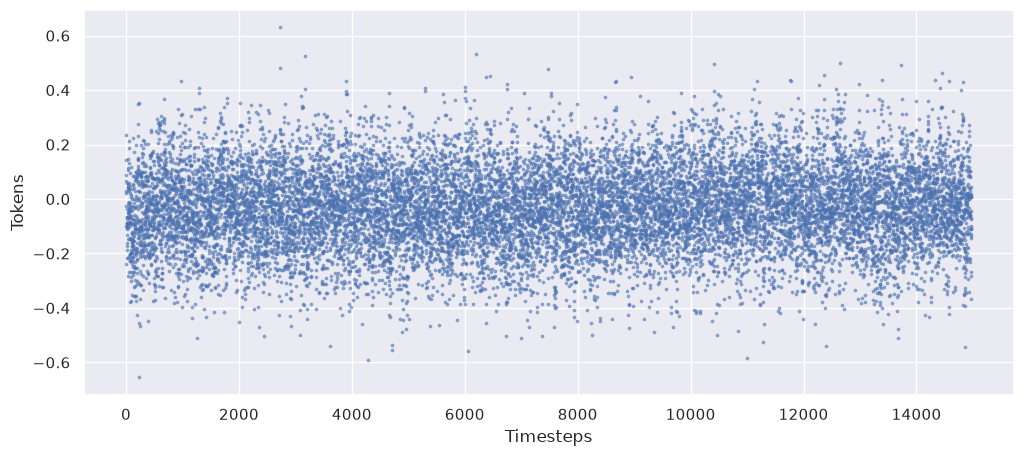

In [48]:
x = np.arange(len(z))
plt.figure(figsize=(12,5))
plt.scatter(x, z[:,0], s=3, alpha=0.5)
plt.xlabel("Timesteps")
plt.ylabel("Tokens")
plt.show()

In [6]:
pca = IncrementalPCA(n_components=100)
B = 512

for i in range(0, len(z), B):
    pca.partial_fit(np.asarray(z[i:i+B], dtype=np.float32))

scores_pca = np.vstack([pca.transform(np.asarray(z[i:i+B], dtype=np.float32))
                        for i in range(0, len(z), B)])

In [7]:
G = np.zeros((N, N), np.float32)
for j in range(0, D, 8192):
    B = z[:, j:j+8192].astype(np.float32)
    G += B @ B.T
ev = np.linalg.eigvalsh(G.astype(np.float64))[::-1] / (N - 1)
explained = ev / ev.sum()                      

In [ ]:
torch.save(scores_pca, "scores_pca.pt")

In [2]:
scores_pca  = torch.load("scores_pca.pt", weights_only=False)

In [15]:
u = umap.UMAP(n_components=10, random_state=42).fit_transform(scores_pca)
for k in range(2, 35):
    lab = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(u)
    print(k,
          round(silhouette_score(u, lab, sample_size=10000, random_state=42), 3),  # higher score is better
          round(calinski_harabasz_score(u, lab)),                                  # higher score is better
          round(davies_bouldin_score(u, lab), 3))                                  # lower score is better

/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


2 0.334 7985 1.3
3 0.327 7402 1.195
4 0.302 6816 1.187
5 0.323 6880 1.12
6 0.347 6780 1.009
7 0.32 6584 1.028
8 0.344 6612 1.022
9 0.339 6616 0.988
10 0.332 6691 0.961
11 0.337 6686 0.967
12 0.332 6609 0.968
13 0.341 6564 0.92
14 0.331 6487 0.935
15 0.331 6517 0.93
16 0.326 6482 0.948
17 0.333 6565 0.915
18 0.336 6495 0.899
19 0.344 6624 0.879
20 0.343 6526 0.892
21 0.339 6470 0.906
22 0.326 6390 0.94
23 0.329 6392 0.936
24 0.337 6325 0.948
25 0.338 6279 0.94
26 0.343 6298 0.946
27 0.327 6233 0.934
28 0.322 6240 0.968
29 0.314 6134 0.976
30 0.332 6217 0.939
31 0.319 6140 0.972
32 0.327 6205 0.913
33 0.325 6121 0.929
34 0.337 6149 0.914


Silhouette Score:  0.33976083993911743


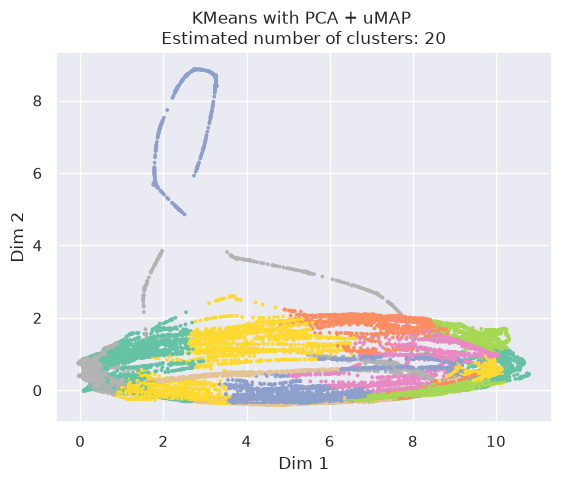

In [33]:
kmeans = KMeans(n_clusters=20,init="k-means++",random_state=3)
labels = kmeans.fit_predict(u)
plt.scatter(u[:,0],u[:,1],c=labels,cmap="Set2",s=3)
print("Silhouette Score: ", silhouette_score(u, labels))

plt.title("KMeans with PCA + uMAP \nEstimated number of clusters: 20")
plt.xlabel("Dim 1")
plt.ylabel("Dim 2")
plt.show()

/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Silhouette Score:  0.2443646639585495


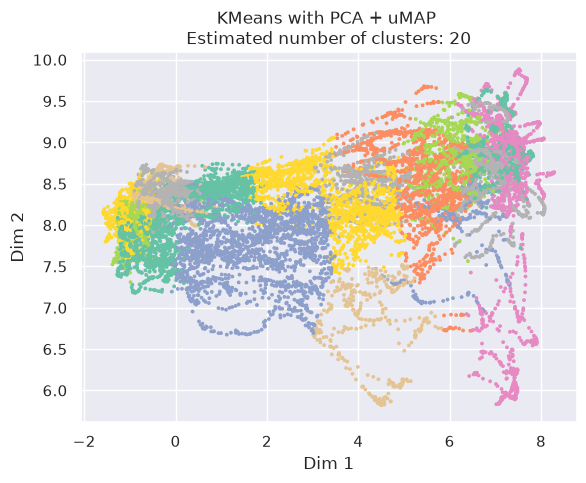

In [10]:
kmeans = KMeans(n_clusters=20,init="k-means++",random_state=3)
scores_pca = StandardScaler().fit_transform(scores_pca)
u = umap.UMAP(n_components=10, random_state=42).fit_transform(scores_pca)
labels = kmeans.fit_predict(u)

plt.scatter(u[:,0],u[:,1],c=labels,cmap="Set2",s=3)
print("Silhouette Score: ", silhouette_score(u, labels))

plt.title("KMeans with PCA + uMAP \nEstimated number of clusters: 20")
plt.xlabel("Dim 1")
plt.ylabel("Dim 2")
plt.show()

Silhouette Score:  0.33976083993911743


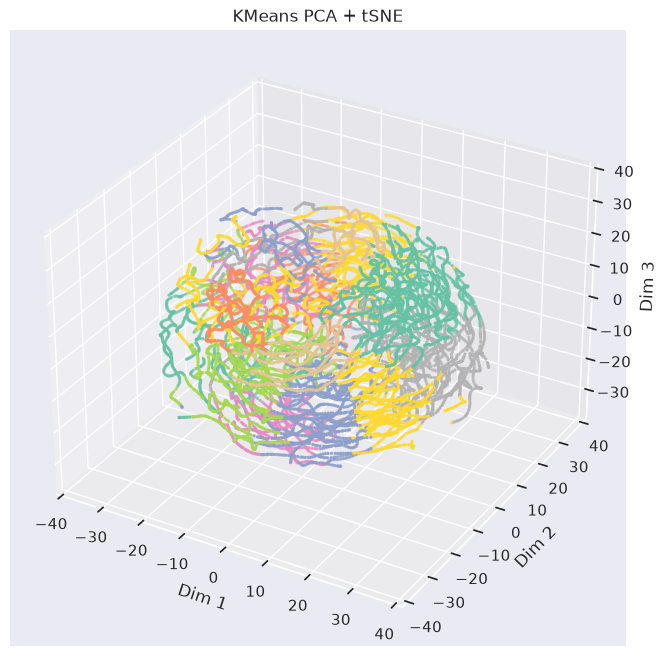

In [ ]:
tsne = TSNE(n_components=3,random_state=3)
t = tsne.fit_transform(scores_pca)
labels = kmeans.fit_predict(u)

print("Silhouette Score: ", silhouette_score(u, labels))
fig = plt.figure(figsize=(10,8))
ax = fig.add_subplot(111,projection="3d")
ax.scatter(t[:,0],t[:,1],t[:,2],c=labels,cmap="Set2",s=2)
ax.set_title("KMeans PCA + tSNE")
ax.set_xlabel("Dim 1")
ax.set_ylabel("Dim 2")
ax.set_zlabel("Dim 3")
plt.show()

/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Silhouette Score:  0.33976083993911743


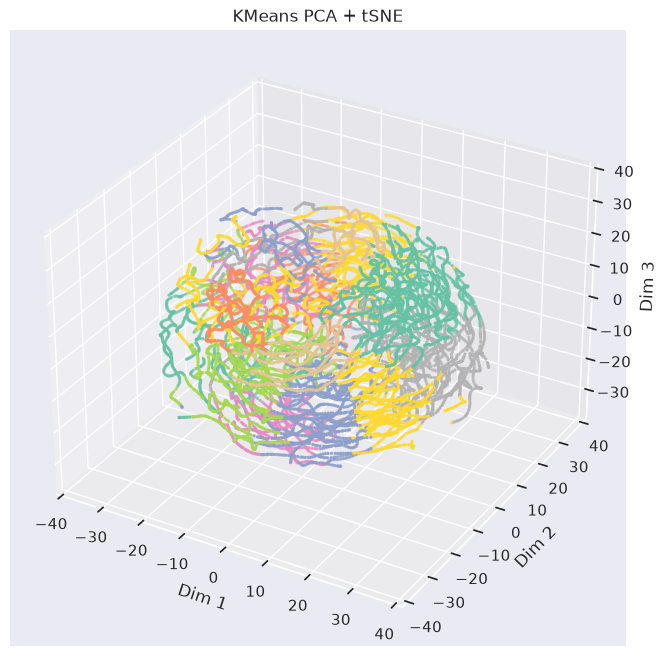

In [14]:
kmeans = KMeans(n_clusters=20,init="k-means++",random_state=3)
tsne = TSNE(n_components=3,random_state=3)
t = tsne.fit_transform(scores_pca)
u = umap.UMAP(n_components=10, random_state=42).fit_transform(scores_pca)
labels = kmeans.fit_predict(u)

print("Silhouette Score: ", silhouette_score(u, labels))
fig = plt.figure(figsize=(10,8))
ax = fig.add_subplot(111,projection="3d")
ax.scatter(t[:,0],t[:,1],t[:,2],c=labels,cmap="Set2",s=2)
ax.set_title("KMeans PCA + tSNE")
ax.set_xlabel("Dim 1")
ax.set_ylabel("Dim 2")
ax.set_zlabel("Dim 3")
plt.show()

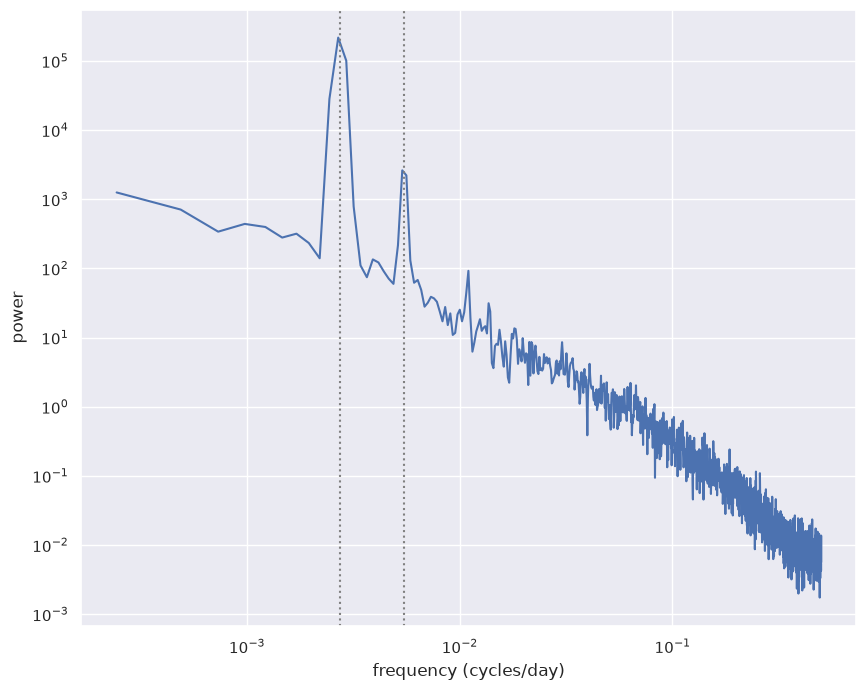

In [7]:
x = scores_pca[:, 0]                                 
f, P = welch(x, fs=1.0, nperseg=4096, detrend="linear")   

plt.figure(figsize=(10,8))
plt.loglog(f[1:], P[1:])
for period in (365.25, 182.6):                         
    plt.axvline(1 / period, ls=":", color="gray")
plt.xlabel("frequency (cycles/day)"); plt.ylabel("power")
plt.show()

In [4]:
from scipy.ndimage import uniform_filter1d

doys = daily["doys"].numpy().astype(int)
g = (doys - 1).clip(0, 365)                          
groups = [np.where(g == k)[0] for k in range(366)]
before = z[:, 0].copy() 
for j in range(0, D, 8192):                          
    B = z[:, j:j+8192]                               
    clim = np.stack([B[ix].mean(0) if len(ix) else np.zeros(B.shape[1], np.float32) for ix in groups])
    clim = uniform_filter1d(clim, size=31, axis=0, mode="wrap")   
    B -= clim[g]

In [6]:
pca = IncrementalPCA(n_components=100)
B = 512

for i in range(0, len(z), B):
    pca.partial_fit(np.asarray(z[i:i+B], dtype=np.float32))

scores_pca_new = np.vstack([pca.transform(np.asarray(z[i:i+B], dtype=np.float32))
                        for i in range(0, len(z), B)])

In [7]:
G = np.zeros((N, N), np.float32)
for j in range(0, D, 8192):
    B = z[:, j:j+8192].astype(np.float32)
    G += B @ B.T
ev = np.linalg.eigvalsh(G.astype(np.float64))[::-1] / (N - 1)
explained = ev / ev.sum()          

In [8]:
torch.save(scores_pca_new, "scores_pca_new.pt")

In [3]:
scores_pca_new  = torch.load("scores_pca_new.pt", weights_only=False)

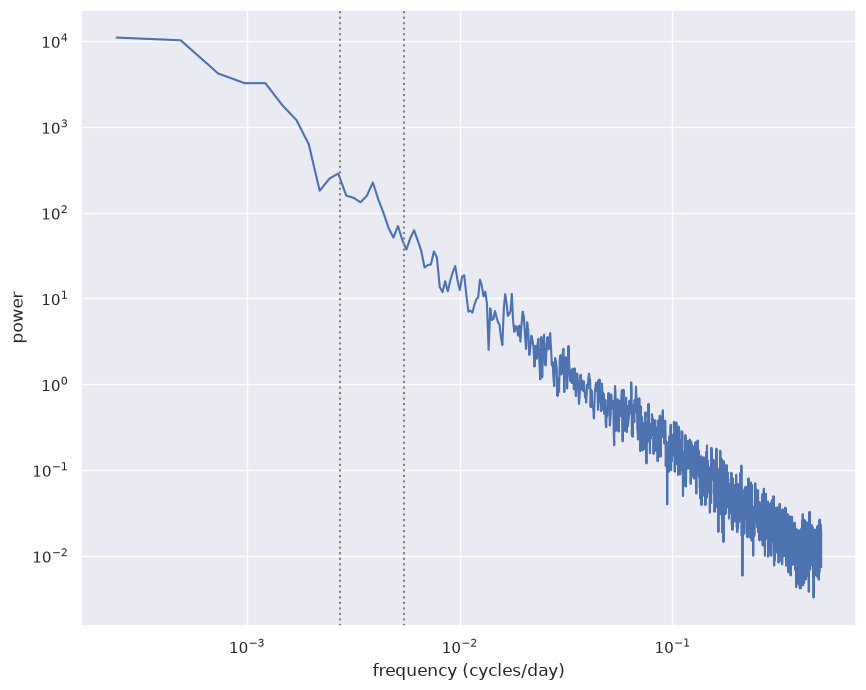

In [6]:
x = scores_pca_new[:, 0]                                 
f, P = welch(x, fs=1.0, nperseg=4096, detrend="linear")   

plt.figure(figsize=(10,8))
plt.loglog(f[1:], P[1:])
for period in (365.25, 182.6):                         
    plt.axvline(1 / period, ls=":", color="gray")
plt.xlabel("frequency (cycles/day)"); plt.ylabel("power")
plt.show()

In [39]:
u = umap.UMAP(n_components=10, random_state=42).fit_transform(scores_pca_new)
for k in range(2, 50):
    lab = KMeans(n_clusters=k, n_init=10, random_state=3).fit_predict(u)
    print(k,
          round(silhouette_score(u, lab), 3),  
          round(calinski_harabasz_score(u, lab)),                                  
          round(davies_bouldin_score(u, lab), 3))                                 

/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


2 0.421 11096 0.844
3 0.379 11171 1.026
4 0.413 12691 0.776
5 0.375 12741 0.981
6 0.387 12127 0.995
7 0.378 11764 0.975
8 0.364 11602 0.992
9 0.366 11370 0.972
10 0.364 10958 1.005
11 0.367 10686 1.007
12 0.362 10389 1.025
13 0.376 10308 0.953
14 0.345 10381 1.029
15 0.342 10306 1.054
16 0.364 10331 0.955
17 0.357 10335 0.993
18 0.365 10292 0.952
19 0.362 10128 0.953
20 0.362 10026 0.956
21 0.367 9967 0.935
22 0.373 10130 0.91
23 0.373 10033 0.908
24 0.37 10032 0.926
25 0.369 9967 0.936
26 0.376 9963 0.91
27 0.375 9971 0.939
28 0.369 9782 0.955
29 0.387 10133 0.903
30 0.388 9895 0.934
31 0.381 9824 0.905
32 0.384 9993 0.977
33 0.393 10010 0.926
34 0.382 9966 0.964
35 0.392 9891 0.904
36 0.392 9908 0.919
37 0.39 10018 0.937
38 0.386 9735 0.91
39 0.39 9930 0.95
40 0.4 9815 0.909
41 0.4 9808 0.92
42 0.386 9696 0.917
43 0.385 9774 0.932
44 0.395 9702 0.931
45 0.39 9662 0.939
46 0.398 9727 0.921
47 0.39 9544 0.918
48 0.397 9656 0.899
49 0.398 9621 0.925


/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Silhouette Score:  0.3906250596046448


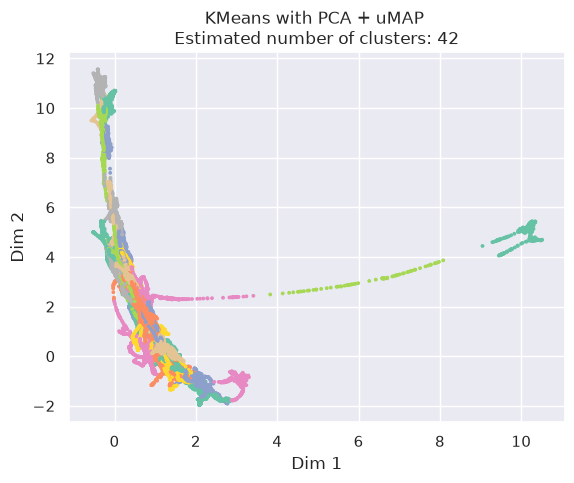

In [18]:
kmeans = KMeans(n_clusters=42,init="k-means++",random_state=3)
u = umap.UMAP(n_components=10, random_state=42).fit_transform(scores_pca_new)
labels = kmeans.fit_predict(u)

plt.scatter(u[:,0],u[:,1],c=labels,cmap="Set2",s=3)
print("Silhouette Score: ", silhouette_score(u, labels))

plt.title("KMeans with PCA + uMAP \nEstimated number of clusters: 42")
plt.xlabel("Dim 1")
plt.ylabel("Dim 2")
plt.show()

/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Silhouette Score:  0.3906250596046448


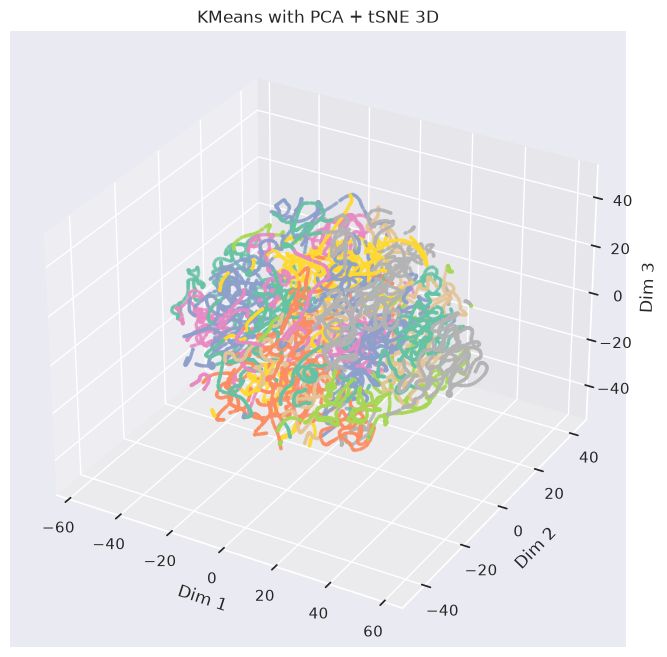

In [45]:
kmeans = KMeans(n_clusters=42,init="k-means++",random_state=3)
u = umap.UMAP(n_components=10, random_state=42).fit_transform(scores_pca_new)
labels = kmeans.fit_predict(u)
tsne = TSNE(n_components=3,random_state=3)
t = tsne.fit_transform(scores_pca_new)

fig = plt.figure(figsize=(10,8))
ax = fig.add_subplot(111,projection="3d")
print("Silhouette Score: ", silhouette_score(u, labels))

ax.scatter(t[:,0],t[:,1],t[:,2],c=labels,cmap="Set2",s=3)
ax.set_title("KMeans with PCA + tSNE 3D")
ax.set_xlabel("Dim 1")
ax.set_ylabel("Dim 2")
ax.set_zlabel("Dim 3")
plt.show()

In [ ]:
B = 512
scaler = StandardScaler()

for i in range(0, len(z), B):
    scaler.partial_fit(np.asarray(z[i:i+B], dtype=np.float32))

for i in range(0, len(z), B):
    block = np.asarray(z[i:i+B], dtype=np.float32)
    z[i:i+B] = scaler.transform(block)

z_scaled = z 

In [7]:
pca_scaled = IncrementalPCA(n_components=100)
B = 512

for i in range(0, len(z), B):
    pca_scaled.partial_fit(np.asarray(z_scaled[i:i+B], dtype=np.float32))

scores_pca_scaled = np.vstack([pca_scaled.transform(np.asarray(z_scaled[i:i+B], dtype=np.float32))
                        for i in range(0, len(z), B)])

In [8]:
torch.save(scores_pca_scaled, "scores_pca_scaled.pt")

In [4]:
scores_pca_scaled  = torch.load("scores_pca_scaled.pt", weights_only=False)

In [11]:
u = umap.UMAP(n_components=10, random_state=42).fit_transform(scores_pca_scaled)
for k in range(2, 50):
    lab = KMeans(n_clusters=k, n_init=10, random_state=3).fit_predict(u)
    print(k,
          round(silhouette_score(u, lab), 3),  
          round(calinski_harabasz_score(u, lab)),                                  
          round(davies_bouldin_score(u, lab), 3))  

/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


2 0.33 7674 1.243
3 0.369 8555 0.893
4 0.365 9869 0.905
5 0.378 10596 0.877
6 0.369 10119 0.936
7 0.338 9527 1.015
8 0.315 9126 1.098
9 0.318 8854 1.14
10 0.305 8597 1.124
11 0.31 8525 1.143
12 0.321 8551 1.088
13 0.332 8490 1.043
14 0.333 8385 0.988
15 0.344 8350 0.98
16 0.34 8311 0.973
17 0.332 8300 0.933
18 0.324 8257 0.966
19 0.326 8251 0.985
20 0.325 8046 0.999
21 0.332 7969 0.984
22 0.331 7990 1.006
23 0.334 7913 0.99
24 0.333 7850 0.988
25 0.341 7785 0.974
26 0.336 7724 1.014
27 0.341 7746 0.969
28 0.337 7614 0.992
29 0.339 7618 1.006
30 0.344 7612 0.991
31 0.339 7507 0.996
32 0.344 7589 0.996
33 0.345 7476 0.98
34 0.358 7556 0.943
35 0.346 7391 0.976
36 0.356 7442 0.918
37 0.352 7452 0.968
38 0.354 7406 0.976
39 0.35 7346 0.992
40 0.353 7238 0.949
41 0.349 7269 0.979
42 0.36 7311 0.928
43 0.359 7289 0.956
44 0.353 7229 0.964
45 0.362 7248 0.946
46 0.356 7224 0.986
47 0.359 7205 0.958
48 0.356 7131 0.967
49 0.353 7214 0.945


/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Silhouette Score:  0.37808313965797424


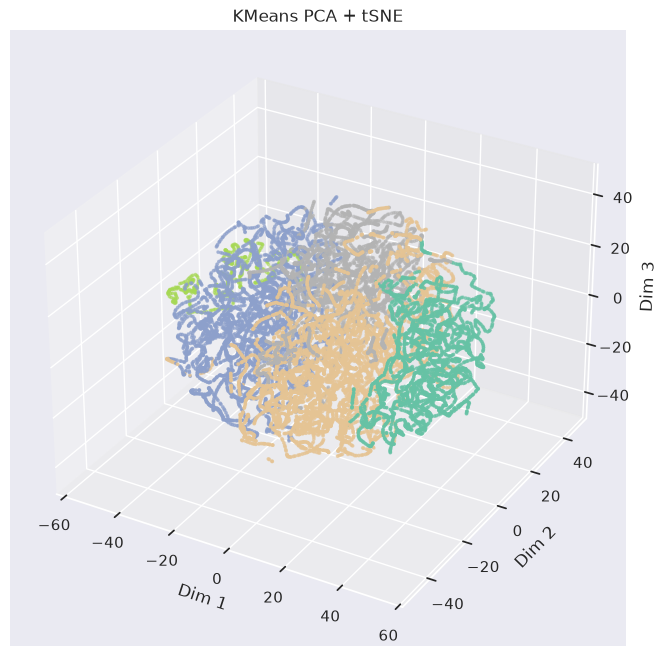

In [18]:
kmeans = KMeans(n_clusters=5,init="k-means++",random_state=3)
u = umap.UMAP(n_components=10, random_state=42).fit_transform(scores_pca_scaled)
labels = kmeans.fit_predict(u)
tsne = TSNE(n_components=3,random_state=3)
t = tsne.fit_transform(scores_pca_scaled)

print("Silhouette Score: ", silhouette_score(u, labels))
fig = plt.figure(figsize=(10,8))
ax =  fig.add_subplot(111,projection="3d")
ax.scatter(t[:,0],t[:,1],t[:,2],c=labels,cmap="Set2",s=3)
ax.set_xlabel("Dim 1")
ax.set_ylabel("Dim 2")
ax.set_zlabel("Dim 3")
ax.set_title("KMeans PCA + tSNE")
plt.show()

In [11]:
rows = []
u = umap.UMAP(n_components=10, random_state=42).fit_transform(scores_pca)
for mcs, ms in itertools.product((50, 100, 200, 400, 800), (5, 10, 20, 50)):
    if ms > mcs:
        continue
    lab = HDBSCAN(min_cluster_size=mcs, min_samples=ms,copy=True).fit_predict(u)
    mask = lab != -1
    k = len(set(lab)) - (1 if -1 in lab else 0)
    sil = (silhouette_score(u[mask], lab[mask], sample_size=10000, random_state=42)
           if k > 1 else np.nan)
    rows.append((mcs, ms, k, round((~mask).mean(), 3), round(sil, 3)))

res = pd.DataFrame(rows, columns=["min_cluster_size", "min_samples", "clusters", "noise", "sil"])
print(res.sort_values("sil", ascending=False))

/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


    min_cluster_size  min_samples  clusters  noise    sil
18               800           20         2  0.863  0.426
14               400           20         3  0.561  0.419
15               400           50         4  0.477  0.341
16               800            5         3  0.477  0.305
11               200           50         2  0.005  0.291
9                200           10         2  0.005  0.291
10               200           20         2  0.005  0.291
4                100            5         2  0.005  0.291
5                100           10         2  0.005  0.291
6                100           20         2  0.005  0.291
8                200            5         2  0.005  0.291
0                 50            5        94  0.310  0.283
13               400           10         5  0.413  0.272
17               800           10         2  0.442  0.254
7                100           50         3  0.016  0.151
2                 50           20         5  0.001  0.052
1             

In [9]:
rows = []
u = umap.UMAP(n_components=10, random_state=42).fit_transform(scores_pca_new)
for mcs, ms in itertools.product((50, 100, 200, 400, 800), (5, 10, 20, 50)):
    if ms > mcs:
        continue
    lab = HDBSCAN(min_cluster_size=mcs, min_samples=ms,copy=True).fit_predict(u)
    mask = lab != -1
    k = len(set(lab)) - (1 if -1 in lab else 0)
    sil = (silhouette_score(u[mask], lab[mask], sample_size=10000, random_state=42)
           if k > 1 else np.nan)
    rows.append((mcs, ms, k, round((~mask).mean(), 3), round(sil, 3)))

res = pd.DataFrame(rows, columns=["min_cluster_size", "min_samples", "clusters", "noise", "sil"])
print(res.sort_values("sil", ascending=False))

/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


    min_cluster_size  min_samples  clusters  noise    sil
19               800           50         2  0.234  0.523
18               800           20         2  0.103  0.502
13               400           10         3  0.041  0.499
17               800           10         2  0.068  0.498
16               800            5         2  0.033  0.495
12               400            5         3  0.006  0.491
7                100           50         2  0.001  0.479
11               200           50         2  0.001  0.479
15               400           50         2  0.001  0.479
10               200           20         2  0.000  0.478
14               400           20         2  0.000  0.478
1                 50           10        84  0.239  0.438
5                100           10        31  0.286  0.419
6                100           20        27  0.267  0.406
8                200            5        21  0.277  0.392
2                 50           20        62  0.271  0.379
4             

In [8]:
rows = []
u = umap.UMAP(n_components=10, random_state=42).fit_transform(scores_pca_scaled)
for mcs, ms in itertools.product((50, 100, 200, 400, 800), (5, 10, 20, 50)):
    if ms > mcs:
        continue
    lab = HDBSCAN(min_cluster_size=mcs, min_samples=ms,copy=True).fit_predict(u)
    mask = lab != -1
    k = len(set(lab)) - (1 if -1 in lab else 0)
    sil = (silhouette_score(u[mask], lab[mask], sample_size=10000, random_state=42)
           if k > 1 else np.nan)
    rows.append((mcs, ms, k, round((~mask).mean(), 3), round(sil, 3)))

res = pd.DataFrame(rows, columns=["min_cluster_size", "min_samples", "clusters", "noise", "sil"])
print(res.sort_values("sil", ascending=False))

/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


    min_cluster_size  min_samples  clusters  noise    sil
3                 50           50         3  0.002  0.579
7                100           50         3  0.002  0.579
11               200           50         2  0.001  0.578
15               400           50         2  0.001  0.578
14               400           20         2  0.000  0.572
13               400           10         2  0.000  0.572
12               400            5         2  0.000  0.572
8                200            5         2  0.000  0.572
10               200           20         2  0.000  0.572
9                200           10         2  0.000  0.572
2                 50           20         3  0.001  0.570
6                100           20         3  0.001  0.570
0                 50            5         3  0.000  0.565
1                 50           10         3  0.000  0.565
5                100           10         3  0.000  0.565
4                100            5         3  0.000  0.565
19            

In [22]:
colors = np.vstack([
    plt.cm.tab20(np.arange(20)),
    plt.cm.tab20b(np.arange(20)),
    plt.cm.tab20c(np.arange(20)),
    plt.cm.nipy_spectral(np.linspace(0.05, 0.95, 20)),   # 4th block: 20 more
])
cmap80 = ListedColormap(colors)

/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Estimated number of clusters: 84
Estimated number of noise points: 3575
Silhouette Score:  0.1458835005760193
Silhouette (no noise): 0.43845459818840027


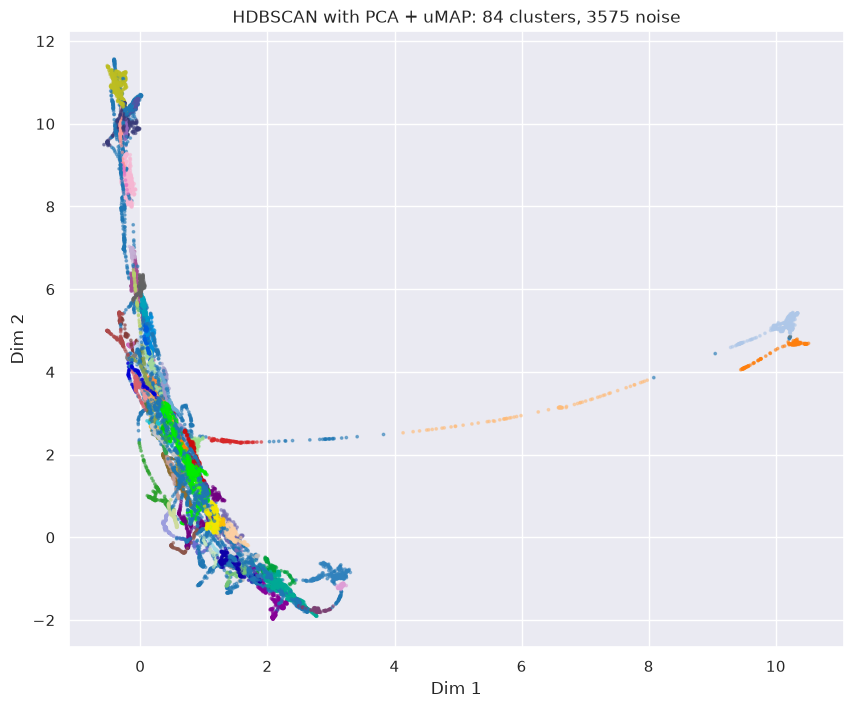

In [28]:
hdbscan = HDBSCAN(min_cluster_size=50, min_samples=10,copy=True)
u = umap.UMAP(n_components=10, random_state=42).fit_transform(scores_pca_new)
labels = hdbscan.fit_predict(u)
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)

print("Estimated number of clusters:", n_clusters_)
print("Estimated number of noise points:", n_noise_)
print("Silhouette Score: ", silhouette_score(u, labels))
mask = labels != -1
print("Silhouette (no noise):", silhouette_score(u[mask], labels[mask], sample_size=10000, random_state=42))

plt.figure(figsize=(10, 8))
plt.scatter(u[:, 0], u[:, 1], c=labels, cmap=cmap80, s=3, alpha=0.5)
plt.title(f"HDBSCAN with PCA + uMAP: {n_clusters_} clusters, {n_noise_} noise")
plt.xlabel("Dim 1")
plt.ylabel("Dim 2")
plt.show()

/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


Estimated number of clusters: 84
Estimated number of noise points: 3575
Silhouette (no noise): 0.43845459818840027


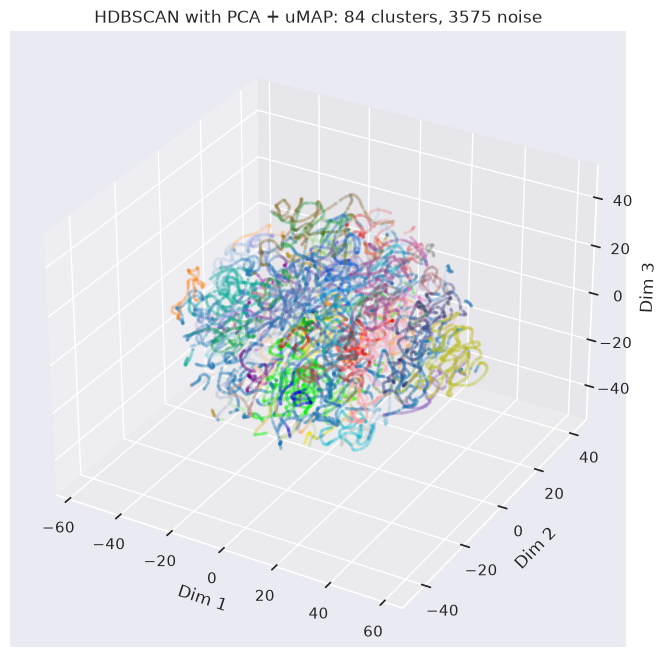

In [27]:
hdbscan = HDBSCAN(min_cluster_size=50, min_samples=10,copy=True)
u = umap.UMAP(n_components=10, random_state=42).fit_transform(scores_pca_new)
labels = hdbscan.fit_predict(u)
n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
n_noise_ = list(labels).count(-1)
tsne = TSNE(n_components=3,random_state=3)
t = tsne.fit_transform(scores_pca_new)

print("Estimated number of clusters:", n_clusters_)
print("Estimated number of noise points:", n_noise_)
mask = labels != -1
print("Silhouette (no noise):", silhouette_score(u[mask], labels[mask], sample_size=10000, random_state=42))

fig  = plt.figure(figsize=(12,8))
ax = fig.add_subplot(111,projection="3d")
ax.scatter(t[:, 0], t[:, 1], t[:,2], c=labels, cmap=cmap80, s=3, alpha=0.5)
ax.set_title(f"HDBSCAN with PCA + uMAP: {n_clusters_} clusters, {n_noise_} noise")
ax.set_xlabel("Dim 1")
ax.set_ylabel("Dim 2")
ax.set_zlabel("Dim 3")
plt.show()


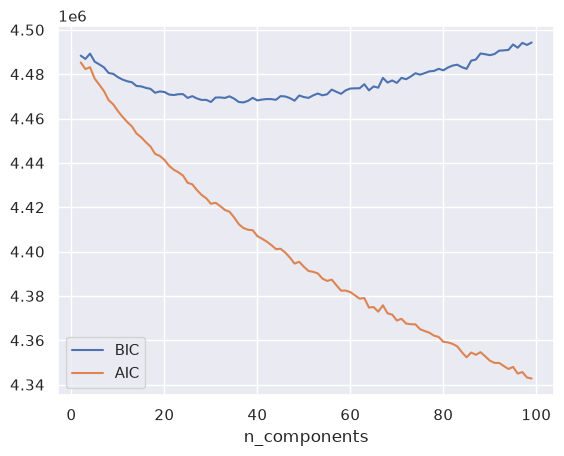

best k by BIC: 37


In [30]:
ks = range(2, 100)
bic, aic = [], []
for k in ks:
    g = GaussianMixture(n_components=k, covariance_type="diag", n_init=3, random_state=42).fit(scores_pca_new)
    bic.append(g.bic(scores_pca_new))
    aic.append(g.aic(scores_pca_new))

plt.plot(ks, bic, label="BIC")
plt.plot(ks, aic, label="AIC")
plt.xlabel("n_components")
plt.legend()
plt.show()
print("best k by BIC:", list(ks)[int(np.argmin(bic))])

In [ ]:
ks = range(2, 100)
bic, aic = [], []
for k in ks:
    g = GaussianMixture(n_components=k, covariance_type="full", n_init=3, random_state=42).fit(scores_pca_new)
    bic.append(g.bic(scores_pca_new))
    aic.append(g.aic(scores_pca_new))

plt.plot(ks, bic, label="BIC")
plt.plot(ks, aic, label="AIC")
plt.xlabel("n_components")
plt.legend()
plt.show()
print("best k by BIC:", list(ks)[int(np.argmin(bic))])

/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/sklearn/mixture/_base.py:293: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(
/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/sklearn/mixture/_base.py:293: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(
/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/sklearn/mixture/_base.py:293: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(
/home/adhin/VSCode/.venv/lib64/python3.14/site-packages/sklearn/mixture/_base.py:293: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or chec